# AI-Based Semiconductor Yield Prediction — Step 1: SECOM Audit

**Georgia Tech ECE 8803 — AI for Semiconductors (Fall 2026)**

**Question:** Can process measurements predict pass/fail manufacturing outcomes? Later, can we compress the classifier into a hardware-efficient, fixed-point RTL implementation?

**Course connections:** Module 2 (fault detection and high-dimensional fab data), Module 5 (process variation), Module 7 (rare-failure screening), and CRISP-DM (data understanding).

**Original UCI labels:** `-1 = pass`, `+1 = fail`. **Our ML labels:** `0 = pass`, `1 = fail`.

> This notebook is exploratory. Later preprocessing (imputation, scaling, selection) will be fitted **only on training data** to prevent data leakage.

In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data" / "raw" / "secom.zip").exists():
    ROOT = ROOT.parent
if not (ROOT / "data" / "raw" / "secom.zip").exists():
    raise FileNotFoundError("Open this notebook from the project folder.")
sys.path.insert(0, str(ROOT))

from src.secom_io import load_secom

X, y, timestamps = load_secom(ROOT / "data" / "raw" / "secom.zip")
print("Sensor matrix:", X.shape)
print("Timestamps:", timestamps.min(), "to", timestamps.max())
display(X.iloc[:5, :8])

Sensor matrix: (1567, 590)
Timestamps: 2008-07-19 11:55:00 to 2008-10-17 06:07:00


,sensor_000,sensor_001,sensor_002,sensor_003,sensor_004,sensor_005,sensor_006,sensor_007
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235


## 1. Rare failures make accuracy misleading

A pass-only classifier scores highly on overall accuracy but catches no failing samples. We will use this as the initial baseline in our modeling phase.

,count
failure,
Pass,1463
Fail,104


Failure rate: 6.64%
Pass-only baseline accuracy: 93.36% (failure recall: 0%)


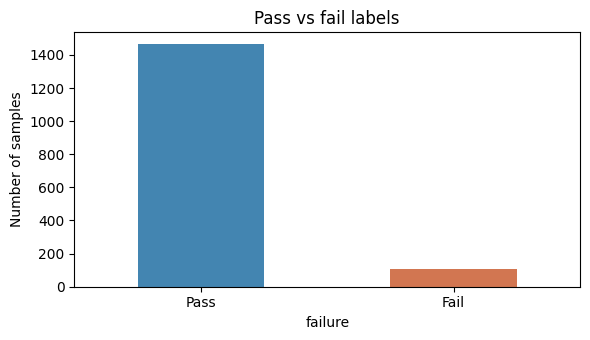

In [2]:
counts = y.value_counts().sort_index().rename(index={0: "Pass", 1: "Fail"})
display(counts.to_frame("count"))
print(f"Failure rate: {100 * (y == 1).mean():.2f}%")
print(f"Pass-only baseline accuracy: {100 * (y == 0).mean():.2f}% (failure recall: 0%)")

fig, ax = plt.subplots(figsize=(6, 3.5))
counts.plot.bar(ax=ax, color=["#4385b1", "#d27651"], rot=0)
ax.set_ylabel("Number of samples")
ax.set_title("Pass vs fail labels")
plt.tight_layout()
plt.show()

## 2. Missing and constant features

SECOM sensor measurements have missing entries. Some columns are constant, so they do not distinguish passing and failing samples. We characterize these issues before fitting models.

,value
Features,590.000
Overall missing cells (%),4.538
Features >= 50% missing,28.000
Constant or empty features,116.000


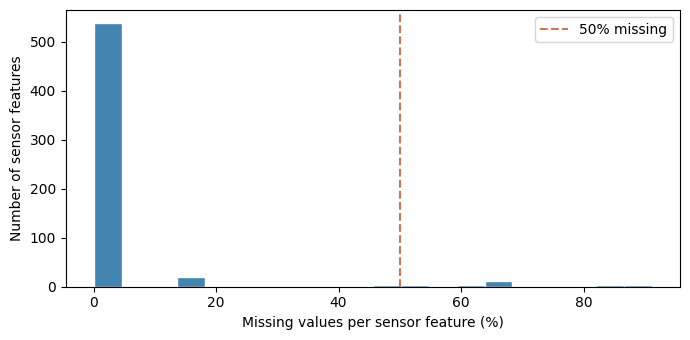

In [3]:
missing = X.isna().mean()
constant = X.nunique(dropna=True).le(1)
summary = pd.Series({
    "Features": X.shape[1],
    "Overall missing cells (%)": round(100 * X.isna().to_numpy().mean(), 3),
    "Features >= 50% missing": int((missing >= 0.5).sum()),
    "Constant or empty features": int(constant.sum()),
})
display(summary.to_frame("value"))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(missing * 100, bins=20, edgecolor="white", color="#4385b1")
ax.axvline(50, linestyle="--", color="#d27651", label="50% missing")
ax.set_xlabel("Missing values per sensor feature (%)")
ax.set_ylabel("Number of sensor features")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Data limitations and decisions for Step 2

- These files contain 590 numeric sensors, a pass/fail label and a test timestamp; they **do not** identify particular sensor physics, lots or chambers.
- We can compare stratified random splitting with time-ordered validation, but not true lot-grouped validation.
- Keep failure class = 1 in all experiments.
- During ML development, evaluate **failure recall**, **false-positive rate**, **PR-AUC**, **balanced accuracy**, and illustrative **escape/overkill cost** in addition to accuracy.
- Choose hardware-friendly features and quantization **after** an appropriate held-out validation design.

Dataset attribution: McCann & Johnston (2008), *SECOM*, UCI Machine Learning Repository, CC BY 4.0, https://doi.org/10.24432/C54305.